# Which tokenizer should BM25 use?

BM25 is only as good as the terms it counts: a query word matches a document only if both sides produce exactly the same string. This notebook keeps BM25 fixed (`k1 = 1.2`, `b = 0.75`) and changes only the tokenizer, building a separate index for each of 17 tokenizers on three very different datasets.

| Dataset | Corpus | Queries | Relevance |
|---|---|---|---|
| BEIR Quora | 522,931 questions | 5,000 dev | binary (duplicate questions) |
| BEIR HotpotQA | 5,233,329 Wikipedia passages | 5,447 dev | binary, 2 passages per query |
| WANDS (Wayfair) | 42,994 products | 480 | graded (Exact 2, Partial 1) |

**The tokenizers, grouped by family**

| Family | Tokenizers | What they do |
|---|---|---|
| Word | Whitespace, Regex `\w+`, NLTK Treebank, NLTK Tweet, spaCy | Split text into words in different ways |
| Normalized | Regex + Porter, Regex + Lemma | Regex words, then stemmed or lemmatized so word forms match |
| Subword | WordPiece (BERT), BPE (RoBERTa), Unigram (T5) | Pretrained vocabularies that split rare words into pieces |
| Char n-gram | 2, 3, 4 and 5-grams | Overlapping letter slices of each word |
| Word n-gram | Word bigrams only | Pairs of neighbouring words |
| Hybrid | Words + bigrams, Words + char 3-grams | Regex words plus extra terms in the same index |

**Short answer:** Regex + Porter had the best nDCG@10 on all three datasets. How you normalize words mattered more than which tokenizer library you use. The full discussion is at the end of the notebook.

## Setup

Install the packages once per environment:

```
%pip install bm25s datasets nltk spacy pandas numpy matplotlib tqdm tokenizers huggingface_hub
```

The subword tokenizers download only vocabulary files from Hugging Face, no model weights. Lucene Standard (`pyserini`, needs Java) and ICU (`PyICU`) are optional and disabled by default.

**Before a full run:** HotpotQA is large. All 17 tokenizers took about 4 hours on it and need a lot of RAM. For a first try, set `DATASETS = ["wands"]`, which finishes in under two minutes.

The next cell holds every setting: datasets, tokenizers, BM25 parameters and retrieval depth.

In [1]:
# Datasets to benchmark, in run order. For a small first run: ["wands"]
DATASETS = ["quora", "hotpotqa", "wands"]

K = 100          # retrieval depth (keep >= 100 for Recall@100 and MAP@100)
BATCH_SIZE = 64  # queries per retrieve() call
TOKEN_BATCH_SIZE = 1024
BM25_PARAMS = dict(method="lucene", k1=1.2, b=0.75)
INDEX_OUTPUT_DIR = None  # Set a directory before running only if you want to save BM25 indices.
# False reproduces the original runner's zero-score padding for nonempty queries.
# True returns only positive-scoring matches for every analyzer.
DROP_ZERO_SCORES = True

# Original six analyzers + eleven new methods. Uncomment optional methods as desired.
ANALYZERS = [
    "Whitespace", "Regex", "NLTK", "spaCy", "Regex_Porter", "Regex_Lemma",
    "Tweet", "WordPiece", "BPE", "Unigram",
    "Char_2gram", "Char_3gram", "Char_4gram", "Char_5gram",
    "Word_1_2gram", "Word_Char_3gram",
    "Word_2gram",  # pure bigram ablation
    # "Lucene_Standard",  # optional: Pyserini + compatible Java
    # "ICU",              # optional: PyICU
]

# Pretrained = BERT, RoBERTa, T5 tokenizer vocabularies (no neural models loaded).
# Train = same corpus-only sample, vocabulary target and pre-tokenizer for all three.
SUBWORD_MODE = "pretrained"  # "pretrained" or "train"
SUBWORD_VOCAB_SIZE = 16000
SUBWORD_TRAIN_DOCS = 100000  # first N corpus documents, same order for each algorithm
OVERLAP_K = 10
RBO_P = 0.9
BASELINE = "Whitespace"
SHOW_FINAL_PLOT = True  # False for a completely plot-free run

AVAILABLE_DATASETS = {"quora", "hotpotqa", "wands"}
assert not set(DATASETS) - AVAILABLE_DATASETS, "Unknown datasets"
assert ANALYZERS and len(ANALYZERS) == len(set(ANALYZERS))
assert SUBWORD_MODE in {"pretrained", "train"}
assert K >= 100 and 0 < OVERLAP_K <= K and 0 < RBO_P < 1
assert min(BATCH_SIZE, TOKEN_BATCH_SIZE, SUBWORD_TRAIN_DOCS, SUBWORD_VOCAB_SIZE) > 0

In [2]:
import gc
import re
import time
import json
from collections import defaultdict
from functools import partial, lru_cache
from itertools import islice, combinations
from pathlib import Path
from IPython.display import display
from importlib.metadata import version, PackageNotFoundError

import bm25s
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import spacy
from datasets import load_dataset
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import TreebankWordTokenizer, TweetTokenizer
from tqdm.auto import tqdm
from datasets.utils import logging as datasets_logging

datasets_logging.set_verbosity_warning()

if "Regex_Lemma" in ANALYZERS:
    nltk.download("wordnet", quiet=True)
    nltk.download("omw-1.4", quiet=True)

all_dataset_results = {}
all_dataset_artifacts = {}

/opt/homebrew/anaconda3/envs/llm_optimization/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Tokenizers

Every tokenizer lowercases the text, and the same function runs on documents and queries, so both sides always produce comparable terms. No stopwords are removed.

- **Word tokenizers** differ in how they treat punctuation and contractions. Whitespace keeps `programming?` as one token, the regex keeps only letters and digits, and NLTK, Tweet and spaCy keep punctuation as separate tokens.
- **Porter and Lemma** run on top of the regex. Porter cuts suffixes with rules (`programmers` → `programm`), and the WordNet lemmatizer looks words up in a dictionary. It gets no part-of-speech tags, so it treats every word as a noun.
- **Subword tokenizers** use the BERT, RoBERTa and T5 vocabularies as plain tokenizers. Their word-start markers (`Ġ`, `▁`) are kept, and unknown tokens are dropped.
- **Character n-grams** slice each word into overlapping n-letter pieces. They never cross word boundaries.
- **Bigrams and hybrids** add extra terms to the regex words with a prefix (`w2:`, `c3:`), so they never collide with ordinary words. They share one index with the words, which also makes documents longer.

In [3]:
treebank = TreebankWordTokenizer()
porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()
nlp = spacy.blank("en")
tweet = TweetTokenizer(preserve_case=True, reduce_len=False, strip_handles=False)


def whitespace_tokenizer(text):
    return text.lower().split()


def regex_tokenizer(text):
    return re.findall(r"\w+", text.lower())


def nltk_tokenizer(text):
    return treebank.tokenize(text.lower())


def spacy_tokenizer(text):
    return [token.text.lower() for token in nlp.make_doc(text) if not token.is_space]


def porter_tokenizer(text):
    return [porter.stem(token) for token in regex_tokenizer(text)]


def lemma_tokenizer(text):
    return [lemmatizer.lemmatize(token) for token in regex_tokenizer(text)]


def tweet_tokenizer(text):
    return tweet.tokenize(text.lower())


def char_ngram_tokenizer(text, n=3):
    return [word[i:i+n] for word in regex_tokenizer(text)
            for i in range(len(word) - n + 1)]


def word_ngram_tokenizer(text, n=2):
    words = regex_tokenizer(text)
    return [f"w{n}:" + " ".join(words[i:i+n]) for i in range(len(words)-n+1)]


def word_unigram_bigram(text):
    return regex_tokenizer(text) + word_ngram_tokenizer(text, 2)


def word_char_trigram(text):
    return regex_tokenizer(text) + ["c3:" + term for term in char_ngram_tokenizer(text, 3)]


@lru_cache(maxsize=1)
def get_lucene_standard():
    from pyserini.analysis import Analyzer
    from pyserini.pyclass import autoclass
    StandardAnalyzer = autoclass("org.apache.lucene.analysis.standard.StandardAnalyzer")
    CharArraySet = autoclass("org.apache.lucene.analysis.CharArraySet")
    return Analyzer(StandardAnalyzer(CharArraySet.EMPTY_SET))


def lucene_standard_tokenizer(text):
    return get_lucene_standard().analyze(text.lower())


def icu_tokenizer(text):
    import icu
    # UnicodeString slices use ICU's UTF-16 offsets, unlike Python str slices.
    source = icu.UnicodeString(text.lower())
    breaker = icu.BreakIterator.createWordInstance(icu.Locale("en"))
    breaker.setText(source)
    start = breaker.first()
    words = []
    for end in breaker:
        if breaker.getRuleStatus() >= 100:  # numbers, letters, kana, ideographs
            words.append(str(source[start:end]))
        start = end
    return words


STATIC_TOKENIZERS = {
    "Whitespace": whitespace_tokenizer,
    "Regex": regex_tokenizer,
    "NLTK": nltk_tokenizer,
    "spaCy": spacy_tokenizer,
    "Regex_Porter": porter_tokenizer,
    "Regex_Lemma": lemma_tokenizer,
    "Tweet": tweet_tokenizer,
    **{f"Char_{i}gram": partial(char_ngram_tokenizer, n=i) for i in range(2, 6)},
    "Word_2gram": word_ngram_tokenizer,
    "Word_1_2gram": word_unigram_bigram,
    "Word_Char_3gram": word_char_trigram,
    "Lucene_Standard": lucene_standard_tokenizer,
    "ICU": icu_tokenizer,
}

SUBWORD_MODELS = {
    "WordPiece": ("bert-base-uncased", "[UNK]"),
    "BPE": ("roberta-base", "<unk>"),
    "Unigram": ("t5-small", "<unk>"),
}
assert not set(ANALYZERS) - (set(STATIC_TOKENIZERS) | set(SUBWORD_MODELS)), "Unknown analyzer"


class SubwordTokenizer:
    def __init__(self, tokenizer, unk_token):
        self.model = tokenizer
        self.unk_token = unk_token

    def _terms(self, encoding):
        return [term for term in encoding.tokens if term != self.unk_token]

    def __call__(self, text):
        return self._terms(self.model.encode(text.lower(), add_special_tokens=False))

    def tokenize_batch(self, texts):
        return [self._terms(enc) for enc in self.model.encode_batch(
            [text.lower() for text in texts], add_special_tokens=False)]


@lru_cache(maxsize=3)
def load_pretrained_subword(name):
    from tokenizers import Tokenizer
    model_id, unk = SUBWORD_MODELS[name]
    model = Tokenizer.from_pretrained(model_id)
    model.no_padding()
    model.no_truncation()
    return SubwordTokenizer(model, unk)


def train_subword(name, corpus_texts, n_docs):
    from tokenizers import Tokenizer, models, trainers, pre_tokenizers
    unk = "[UNK]"
    common = dict(vocab_size=SUBWORD_VOCAB_SIZE, special_tokens=[unk], show_progress=False)
    if name == "WordPiece":
        model = models.WordPiece(unk_token=unk)
        trainer = trainers.WordPieceTrainer(**common, min_frequency=1)
    elif name == "BPE":
        model = models.BPE(unk_token=unk)
        trainer = trainers.BpeTrainer(**common, min_frequency=1)
    elif name == "Unigram":
        model = models.Unigram()
        trainer = trainers.UnigramTrainer(**common, unk_token=unk)
    else:
        raise ValueError(name)
    tok = Tokenizer(model)
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    sample_size = min(n_docs, SUBWORD_TRAIN_DOCS)
    # Same deterministic prefix sample for all three methods; no qrels or queries.
    tok.train_from_iterator((text.lower() for text in islice(corpus_texts(), sample_size)),
                            trainer=trainer, length=sample_size)
    return SubwordTokenizer(tok, unk)


def iter_tokenized(texts, tokenizer, total, desc):
    iterator = iter(texts)
    with tqdm(total=total, desc=desc, leave=False) as progress:
        while True:
            batch = list(islice(iterator, TOKEN_BATCH_SIZE))
            if not batch:
                break
            if hasattr(tokenizer, "tokenize_batch"):
                encoded = tokenizer.tokenize_batch(batch)
            else:
                encoded = [tokenizer(text) for text in batch]
            yield from encoded
            progress.update(len(batch))

### Example

The same question through every tokenizer. This shows the differences the benchmark measures: punctuation glued to words, split contractions, subword markers and how many terms each method creates.

In [4]:
example = "What's the best way to learn machine-learning?"
print(f"Input: {example}\n")

# Corpus-trained subwords are fitted later, so no pretrained stand-in is shown.
for name in ANALYZERS:
    if name in STATIC_TOKENIZERS:
        tokenizer = STATIC_TOKENIZERS[name]
    elif SUBWORD_MODE == "pretrained":
        tokenizer = load_pretrained_subword(name)
    else:
        continue
    print(f"{name:20} {tokenizer(example)}")

Input: What's the best way to learn machine-learning?

Whitespace           ["what's", 'the', 'best', 'way', 'to', 'learn', 'machine-learning?']
Regex                ['what', 's', 'the', 'best', 'way', 'to', 'learn', 'machine', 'learning']
NLTK                 ['what', "'s", 'the', 'best', 'way', 'to', 'learn', 'machine-learning', '?']
spaCy                ['what', "'s", 'the', 'best', 'way', 'to', 'learn', 'machine', '-', 'learning', '?']
Regex_Porter         ['what', 's', 'the', 'best', 'way', 'to', 'learn', 'machin', 'learn']
Regex_Lemma          ['what', 's', 'the', 'best', 'way', 'to', 'learn', 'machine', 'learning']
Tweet                ["what's", 'the', 'best', 'way', 'to', 'learn', 'machine-learning', '?']


WordPiece            ['what', "'", 's', 'the', 'best', 'way', 'to', 'learn', 'machine', '-', 'learning', '?']
BPE                  ['what', "'s", 'Ġthe', 'Ġbest', 'Ġway', 'Ġto', 'Ġlearn', 'Ġmachine', '-', 'learning', '?']
Unigram              ['▁what', "'", 's', '▁the', '▁best', '▁way', '▁to', '▁learn', '▁machine', '-', 'learning', '?']
Char_2gram           ['wh', 'ha', 'at', 'th', 'he', 'be', 'es', 'st', 'wa', 'ay', 'to', 'le', 'ea', 'ar', 'rn', 'ma', 'ac', 'ch', 'hi', 'in', 'ne', 'le', 'ea', 'ar', 'rn', 'ni', 'in', 'ng']
Char_3gram           ['wha', 'hat', 'the', 'bes', 'est', 'way', 'lea', 'ear', 'arn', 'mac', 'ach', 'chi', 'hin', 'ine', 'lea', 'ear', 'arn', 'rni', 'nin', 'ing']
Char_4gram           ['what', 'best', 'lear', 'earn', 'mach', 'achi', 'chin', 'hine', 'lear', 'earn', 'arni', 'rnin', 'ning']
Char_5gram           ['learn', 'machi', 'achin', 'chine', 'learn', 'earni', 'arnin', 'rning']
Word_1_2gram         ['what', 's', 'the', 'best', 'way', 'to', 'learn', 'machine', 'learn

## Evaluation Metrics

- **nDCG@10**: the main metric. It rewards relevant results near the top. WANDS uses graded gains (Exact counts more than Partial).
- **MRR@10**: how high the first relevant result appears. On WANDS only Exact matches count.
- **Recall@100**: the share of relevant documents in the top 100, which is what a reranker would get to see.
- **Precision@10** and **MAP@100** are also reported. HotpotQA adds **Both@10**: both supporting passages are in the top 10.

On WANDS each query has many relevant products, so Recall@10 and Recall@100 stay low for every tokenizer. Compare them across tokenizers, not against the other datasets.

In [5]:
def evaluate_binary(retrieved_ids, query_qrels, both_at_10=False):
    relevant = {
        str(doc_id)
        for doc_id, score in query_qrels.items()
        if score > 0
    }

    if not relevant:
        return None

    top_10 = retrieved_ids[:10]

    recall_100 = len(set(retrieved_ids[:100]) & relevant) / len(relevant)

    mrr_10 = 0.0
    for rank, doc_id in enumerate(top_10, start=1):
        if doc_id in relevant:
            mrr_10 = 1.0 / rank
            break

    rels = np.array([int(doc_id in relevant) for doc_id in top_10])
    dcg = np.sum(rels / np.log2(np.arange(2, len(rels) + 2)))

    ideal_count = min(len(relevant), 10)
    idcg = np.sum(1 / np.log2(np.arange(2, ideal_count + 2)))

    metrics = {
        "nDCG@10": dcg / idcg if idcg > 0 else 0.0,
        "MRR@10": mrr_10,
        "Recall@100": recall_100,
    }

    if both_at_10:
        metrics["Both@10"] = float(relevant.issubset(set(top_10)))

    return metrics


def dcg_at_k(relevances, k):
    rel = np.asarray(relevances[:k], dtype=float)

    if len(rel) == 0:
        return 0.0

    discounts = np.log2(np.arange(2, len(rel) + 2))

    return float(np.sum((2 ** rel - 1) / discounts))


def evaluate_graded(retrieved_ids, query_qrels):
    # Known relevant documents (Exact or Partial)
    relevant = {pid for pid, rel in query_qrels.items() if rel > 0}
    exact = {pid for pid, rel in query_qrels.items() if rel == 2}

    recall_10 = (
        len(set(retrieved_ids[:10]) & relevant) / len(relevant)
        if relevant else np.nan
    )

    recall_100 = (
        len(set(retrieved_ids[:100]) & relevant) / len(relevant)
        if relevant else np.nan
    )

    # MRR@10 (Exact-only)
    mrr_10 = np.nan
    if exact:
        mrr_10 = 0.0
        for rank, pid in enumerate(retrieved_ids[:10], start=1):
            if pid in exact:
                mrr_10 = 1.0 / rank
                break

    ranked_rels = [query_qrels.get(pid, 0) for pid in retrieved_ids[:10]]
    ideal_dcg = dcg_at_k(sorted(query_qrels.values(), reverse=True), 10)

    ndcg_10 = (
        dcg_at_k(ranked_rels, 10) / ideal_dcg
        if ideal_dcg > 0 else np.nan
    )

    return {
        "nDCG@10": ndcg_10,
        "MRR@10": mrr_10,
        "Recall@10": recall_10,
        "Recall@100": recall_100,
    }

def extra_binary_metrics(retrieved_ids, query_qrels):
    relevant = {str(doc_id) for doc_id, score in query_qrels.items() if score > 0}
    if not relevant:
        return {"Precision@10": np.nan, "MAP@100": np.nan}
    hits = 0
    ap_sum = 0.0
    for rank, doc_id in enumerate(retrieved_ids[:100], 1):
        if doc_id in relevant:
            hits += 1
            ap_sum += hits / rank
    return {
        "Precision@10": len(set(retrieved_ids[:10]) & relevant) / 10,
        "MAP@100": ap_sum / min(100, len(relevant)),
    }


def ranking_overlap(a, b, k=OVERLAP_K, p=RBO_P):
    """Jaccard@k and finite extrapolated RBO; both-empty = undefined.
    Missing ranks contribute no items. Depth is capped at k and the longer list.
    """
    a, b = a[:k], b[:k]
    union = set(a) | set(b)
    if not union:
        return np.nan, np.nan
    jaccard = len(set(a) & set(b)) / len(union)
    depth = max(len(a), len(b))
    agreements = [len(set(a[:d]) & set(b[:d])) / d for d in range(1, depth+1)]
    rbo = (1-p)*sum(p**i * v for i, v in enumerate(agreements)) + p**depth*agreements[-1]
    return jaccard, rbo


def pairwise_overlap(rankings, query_ids):
    rows = []
    total_pairs = len(rankings) * (len(rankings) - 1) // 2
    for a, b in tqdm(combinations(rankings, 2), total=total_pairs,
                     desc="Ranking overlap", leave=False, disable=total_pairs == 0):
        values = np.asarray([ranking_overlap(rankings[a][qid], rankings[b][qid])
                             for qid in query_ids])
        valid = ~np.isnan(values[:, 0])
        averages = values[valid].mean(axis=0) if valid.any() else [np.nan, np.nan]
        rows.append({"TokenizerA": a, "TokenizerB": b,
                     f"Jaccard@{OVERLAP_K}": averages[0],
                     f"RBO@{OVERLAP_K}": averages[1], "ComparedQueries": int(valid.sum())})
    return pd.DataFrame(rows, columns=["TokenizerA", "TokenizerB", f"Jaccard@{OVERLAP_K}",
                                        f"RBO@{OVERLAP_K}", "ComparedQueries"])

## Benchmark Runner

One function runs the same steps for every dataset and tokenizer:

1. Tokenize the whole corpus.
2. Build a separate BM25 index.
3. Tokenize the queries with the same tokenizer.
4. Retrieve the top 100 documents per query.
5. Score them against the relevance labels.

It also records timings, vocabulary size, average document length, query terms missing from the index, and how much each ranking overlaps with the Whitespace ranking. Results stay in memory; nothing is written to disk unless you call the export function at the end.

In [6]:
def run_benchmark(dataset_name, corpus_texts, n_docs, doc_ids, query_ids,
                  query_texts, qrels, evaluate_fn):
    """corpus_texts is a repeatable zero-argument iterable factory in doc_ids order."""
    assert n_docs == len(doc_ids) and n_docs > 0
    assert len(query_ids) == len(query_texts) and len(query_ids) > 0
    assert len(set(query_ids)) == len(query_ids)
    k = min(K, n_docs)
    index_dir = (Path(INDEX_OUTPUT_DIR) / dataset_name
                 if INDEX_OUTPUT_DIR is not None else None)
    models_to_export = {}
    packages = {}
    for package in ["bm25s", "nltk", "spacy", "tokenizers", "datasets", "numpy", "pandas", "pyserini", "PyICU"]:
        try:
            packages[package] = version(package)
        except PackageNotFoundError:
            packages[package] = None
    config = {
        "dataset": dataset_name, "n_docs": n_docs, "n_queries": len(query_ids),
        "analyzers": ANALYZERS, "bm25": BM25_PARAMS, "k": k, "batch_size": BATCH_SIZE,
        "token_batch_size": TOKEN_BATCH_SIZE, "drop_zero_scores": DROP_ZERO_SCORES,
        "save_indices": index_dir is not None, "subword_mode": SUBWORD_MODE,
        "subword_vocab_target": SUBWORD_VOCAB_SIZE, "subword_train_docs": SUBWORD_TRAIN_DOCS,
        "pretrained_models": SUBWORD_MODELS, "overlap_k": OVERLAP_K, "rbo_p": RBO_P,
        "baseline": BASELINE, "packages": packages,
    }
    all_results, per_query_results, rankings = [], [], {}

    progress = tqdm(ANALYZERS, desc=dataset_name.upper(), unit="analyzer")
    for name in progress:
        progress.set_postfix_str(f"{name} | preparing")
        training_time = 0.0
        model_vocab_size = np.nan
        if name in SUBWORD_MODELS:
            if SUBWORD_MODE == "train":
                progress.set_postfix_str(f"{name} | training")
                start = time.perf_counter()
                tokenizer = train_subword(name, corpus_texts, n_docs)
                training_time = time.perf_counter() - start
            else:
                tokenizer = load_pretrained_subword(name)
            models_to_export[name] = tokenizer.model
            model_vocab_size = tokenizer.model.get_vocab_size()
        else:
            tokenizer = STATIC_TOKENIZERS[name]

        # 1. Corpus tokenization: encode to compact IDs using one shared vocabulary.
        progress.set_postfix_str(f"{name} | tokenizing")
        start = time.perf_counter()
        vocab, corpus_ids = {}, []
        token_count = empty_docs = 0
        for terms in iter_tokenized(corpus_texts(), tokenizer, n_docs, f"Tokenizing {name}"):
            token_count += len(terms)
            empty_docs += not terms
            corpus_ids.append([vocab.setdefault(term, len(vocab)) for term in terms])
        tokenization_time = time.perf_counter() - start
        assert len(corpus_ids) == n_docs, "Corpus length changed between runs"
        vocab_size = len(vocab)
        if not vocab_size:
            raise ValueError(f"{name} produced no corpus terms")

        # 2. Build the independent index using bm25s' (token IDs, vocabulary) API.
        start = time.perf_counter()
        retriever = bm25s.BM25(**BM25_PARAMS)
        progress.set_postfix_str(f"{name} | indexing")
        retriever.index((corpus_ids, vocab), show_progress=False)
        indexing_time = time.perf_counter() - start
        del corpus_ids, vocab
        gc.collect()

        # 3. Save index (optional). Size excludes saved subword model and results.
        index_size = np.nan
        if index_dir is not None:
            progress.set_postfix_str(f"{name} | saving index")
            target = index_dir / name
            if target.exists():
                raise FileExistsError(f"Index already exists: {target}. Choose a new INDEX_OUTPUT_DIR.")
            target.parent.mkdir(parents=True, exist_ok=True)
            retriever.save(str(target))
            index_size = sum(p.stat().st_size for p in target.rglob("*") if p.is_file()) / 2**20

        # 4. Tokenize queries and calculate occurrence-based OOV, before filtering.
        progress.set_postfix_str(f"{name} | queries")
        start = time.perf_counter()
        query_tokens = list(iter_tokenized(query_texts, tokenizer, len(query_ids), f"Queries {name}"))
        query_tokenization_time = time.perf_counter() - start
        in_vocab = retriever.vocab_dict
        query_term_count = sum(map(len, query_tokens))
        missing_terms = sum(term not in in_vocab for terms in query_tokens for term in terms)
        # Avoid bm25s arbitrary all-zero rankings for empty or entirely OOV queries.
        filtered_queries = [[term for term in terms if term in in_vocab] for terms in query_tokens]
        empty_queries = sum(not terms for terms in query_tokens)
        unmatched_queries = sum(not terms for terms in filtered_queries)

        # 5. Retrieve batches, keeping the original query order.
        query_metrics, retrieval_time = [], 0.0
        rankings[name] = {}
        progress.set_postfix_str(f"{name} | retrieval")
        for batch_start in tqdm(range(0, len(query_tokens), BATCH_SIZE), desc=f"Retrieving {name}", leave=False):
            batch = filtered_queries[batch_start:batch_start+BATCH_SIZE]
            active = [i for i, terms in enumerate(batch) if terms]
            ranked = {}
            if active:
                start = time.perf_counter()
                doc_indices, scores = retriever.retrieve([batch[i] for i in active], k=k, show_progress=False)
                retrieval_time += time.perf_counter() - start
                for local_idx, indices, values in zip(active, doc_indices, scores):
                    ranked[local_idx] = [doc_ids[int(i)] for i, score in zip(indices, values)
                                         if not DROP_ZERO_SCORES or score > 0]
            for local_idx in range(len(batch)):
                query_idx = batch_start + local_idx
                qid = query_ids[query_idx]
                retrieved_ids = ranked.get(local_idx, [])
                rankings[name][qid] = retrieved_ids[:OVERLAP_K]
                judgments = qrels.get(qid, {})
                metrics = evaluate_fn(retrieved_ids, judgments)
                if metrics is None:
                    continue
                metrics.update(extra_binary_metrics(retrieved_ids, judgments))
                query_metrics.append(metrics)
                row = {"Tokenizer": name, "query_id": qid, "query": query_texts[query_idx],
                       "QueryTokens": len(query_tokens[query_idx]),
                       "QueryOOVRate": (1-len(batch[local_idx])/len(query_tokens[query_idx])
                                        if query_tokens[query_idx] else np.nan),
                       "RetrievedDocs": len(retrieved_ids), **metrics}
                per_query_results.append(row)

        # 6. Aggregate metrics in memory.
        metric_df = pd.DataFrame(query_metrics)
        if metric_df.empty:
            raise ValueError("No evaluated queries. Check query/qrels IDs.")
        result = {
            "Tokenizer": name, **metric_df.mean().to_dict(),
            "VocabularySize": vocab_size, "ModelVocabularySize": model_vocab_size,
            "TotalTokens": token_count, "AvgDocLength": token_count/n_docs,
            "EmptyDocRate": empty_docs/n_docs,
            "AvgQueryTokens": query_term_count/len(query_ids),
            "QueryOOVRate": missing_terms/query_term_count if query_term_count else np.nan,
            "EmptyQueryRate": empty_queries/len(query_ids),
            "NoMatchingTokenQueryRate": unmatched_queries/len(query_ids),
            "IndexSize(MiB)": index_size, "TrainingTime(s)": training_time,
            "TokenizationTime(s)": tokenization_time, "IndexTime(s)": indexing_time,
            "AvgQueryTime(ms)": retrieval_time/len(query_ids)*1000,
            "QueryTokenizationTime(s)": query_tokenization_time,
            "EvaluatedQueries": int(metric_df["nDCG@10"].notna().sum()),
        }
        all_results.append(result)
        del retriever, in_vocab, query_tokens, filtered_queries, tokenizer
        gc.collect()
        progress.set_postfix_str("")

    results_df = pd.DataFrame(all_results).sort_values("nDCG@10", ascending=False).reset_index(drop=True)
    overlap_df = pairwise_overlap(rankings, query_ids)
    # Include baseline overlap in the aggregate table, if the baseline was selected.
    if BASELINE in rankings:
        for i, row in results_df.iterrows():
            vals = np.asarray([ranking_overlap(rankings[BASELINE][qid], rankings[row["Tokenizer"]][qid])
                               for qid in query_ids])
            valid = ~np.isnan(vals[:, 0])
            avg = vals[valid].mean(axis=0) if valid.any() else [np.nan, np.nan]
            results_df.loc[i, f"Jaccard@{OVERLAP_K}_vs_{BASELINE}"] = avg[0]
            results_df.loc[i, f"RBO@{OVERLAP_K}_vs_{BASELINE}"] = avg[1]
    per_query_df = pd.DataFrame(per_query_results)
    all_dataset_artifacts[dataset_name] = {
        "per_query": per_query_df,
        "overlap": overlap_df,
        "rankings": rankings,
        "config": config,
        "models": models_to_export,
    }
    return results_df, per_query_df

## Sanity Checks

A few quick assertions on the tokenizers, the metrics and a three-document BM25 index. They run in seconds and catch environment problems before the long benchmark starts.

In [7]:
assert regex_tokenizer("C++ & Tables") == ["c", "tables"]
assert char_ngram_tokenizer("ab cde", 3) == ["cde"]
assert word_ngram_tokenizer("A B C") == ["w2:a b", "w2:b c"]
assert word_char_trigram("table") == ["table", "c3:tab", "c3:abl", "c3:ble"]
assert np.allclose(ranking_overlap(["a", "b"], ["a", "b"]), (1.0, 1.0))
assert ranking_overlap(["a"], ["b"]) == (0.0, 0.0)
assert np.isnan(ranking_overlap([], [])[0])
assert extra_binary_metrics(["a"], {"a": 1}) == {"Precision@10": 0.1, "MAP@100": 1.0}
assert evaluate_binary([], {"a": 1})["nDCG@10"] == 0
assert evaluate_graded(["a"], {"a": 2})["nDCG@10"] == 1

mini_vocab = {}
mini_docs = [[mini_vocab.setdefault(t, len(mini_vocab)) for t in regex_tokenizer(s)]
             for s in ["red table", "blue chair", "wooden table"]]
mini = bm25s.BM25(**BM25_PARAMS)
mini.index((mini_docs, mini_vocab), show_progress=False)
ids, scores = mini.retrieve([["chair"]], k=3, show_progress=False)
assert int(ids[0, 0]) == 1 and scores[0, 0] > 0
del mini, mini_docs, mini_vocab

---
## Dataset 1: BEIR Quora

Short questions where the task is finding duplicates: another wording of the same question. The same idea is often written with different word forms, so this dataset rewards anything that makes `program`, `programs` and `programmers` match.

### Load Data

Load the corpus, queries and dev relevance labels from Hugging Face. Document text is `title + text`.

In [8]:
if "quora" in DATASETS:
    corpus_ds = load_dataset("BeIR/quora", "corpus", split="corpus")
    queries_ds = load_dataset("BeIR/quora", "queries", split="queries")
    qrels_dev_ds = load_dataset("BeIR/quora-qrels", split="validation")

    # Preserve document order
    doc_ids = [str(x) for x in corpus_ds["_id"]]

    doc_texts = [
        f"{title or ''} {text or ''}".strip()
        for title, text in zip(corpus_ds["title"], corpus_ds["text"])
    ]

    all_queries = {
        str(qid): text
        for qid, text in zip(queries_ds["_id"], queries_ds["text"])
    }

    qrels = defaultdict(dict)
    for row in qrels_dev_ds:
        qrels[str(row["query-id"])][str(row["corpus-id"])] = int(row["score"])
    qrels = dict(qrels)

    # Development queries = queries that have dev judgments
    query_ids = list(qrels)
    query_texts = [all_queries[qid] for qid in query_ids]

### Indexing and Evaluation

Run all tokenizers on Quora. The table is sorted by nDCG@10.

In [9]:
if "quora" in DATASETS:
    quora_results_df, quora_per_query_df = run_benchmark(
        "quora",
        corpus_texts=lambda: doc_texts,
        n_docs=len(doc_texts),
        doc_ids=doc_ids,
        query_ids=query_ids,
        query_texts=query_texts,
        qrels=qrels,
        evaluate_fn=evaluate_binary,
    )

    all_dataset_results["quora"] = quora_results_df
    with pd.option_context("display.max_columns", None, "display.max_rows", None):
        display(quora_results_df)

    # Free the corpus before the next dataset
    del corpus_ds, queries_ds, qrels_dev_ds, doc_ids, doc_texts, all_queries
    gc.collect()

QUORA: 100%|██████████| 17/17 [07:18<00:00, 25.80s/analyzer]                              


,Tokenizer,nDCG@10,MRR@10,Recall@100,Precision@10,MAP@100,VocabularySize,ModelVocabularySize,TotalTokens,AvgDocLength,EmptyDocRate,AvgQueryTokens,QueryOOVRate,EmptyQueryRate,NoMatchingTokenQueryRate,IndexSize(MiB),TrainingTime(s),TokenizationTime(s),IndexTime(s),AvgQueryTime(ms),QueryTokenizationTime(s),EvaluatedQueries,Jaccard@10_vs_Whitespace,RBO@10_vs_Whitespace
0,Regex_Porter,0.796175,0.790685,0.973038,0.11982,0.755948,65409,NaN,6100704,11.666365,0.000027,9.6762,0.000971,0.0000,0.0000,NaN,0.0,19.760279,2.589899,3.158940,0.155647,5000,0.361034,0.522984
1,Word_Char_3gram,0.791120,0.783630,0.970524,0.11908,0.749794,103343,NaN,20441655,39.090540,0.000027,32.4914,0.000579,0.0000,0.0000,NaN,0.0,3.212578,5.509524,3.996869,0.016638,5000,0.305481,0.477774
2,Regex_Lemma,0.776735,0.772842,0.964581,0.11648,0.736382,78664,NaN,6100704,11.666365,0.000027,9.6762,0.001550,0.0000,0.0000,NaN,0.0,6.390783,2.588779,3.130759,0.046473,5000,0.402672,0.562034
3,Char_3gram,0.763893,0.757964,0.955038,0.11484,0.723929,17235,NaN,14340951,27.424175,0.000076,22.8152,0.000079,0.0000,0.0000,NaN,0.0,2.028608,4.211835,3.559338,0.010777,5000,0.225284,0.387687
4,Unigram,0.757642,0.751456,0.957525,0.11448,0.715174,17535,32100.0,8595384,16.436937,0.000000,13.4296,0.000045,0.0000,0.0000,NaN,0.0,3.798881,3.064917,4.081284,0.027574,5000,0.369181,0.539886
5,WordPiece,0.750595,0.745997,0.955344,0.11332,0.708777,25843,30522.0,7465857,14.276945,0.000000,11.7086,0.000034,0.0000,0.0000,NaN,0.0,3.038234,2.930158,3.666378,0.020542,5000,0.397336,0.563850
6,Regex,0.743370,0.740226,0.948401,0.11208,0.701390,86108,NaN,6100704,11.666365,0.000027,9.6762,0.001757,0.0000,0.0000,NaN,0.0,0.987848,2.589680,3.123427,0.004781,5000,0.460462,0.615861
7,BPE,0.742358,0.736821,0.948877,0.11240,0.698823,30402,50265.0,7568830,14.473860,0.000000,11.8852,0.000135,0.0000,0.0000,NaN,0.0,3.237507,2.954818,3.544952,0.022203,5000,0.389899,0.558886
8,spaCy,0.741126,0.737916,0.946700,0.11172,0.698728,96302,NaN,6874474,13.146044,0.000000,10.9070,0.002054,0.0000,0.0000,NaN,0.0,8.228406,2.746050,3.645652,0.068745,5000,0.461535,0.617310
9,Char_2gram,0.738783,0.732099,0.943242,0.11128,0.697586,3147,NaN,20033587,38.310192,0.000046,31.9328,0.000013,0.0000,0.0000,NaN,0.0,2.307051,4.735197,6.606579,0.012033,5000,0.207168,0.370136


**What Quora shows**

- The regex beats whitespace by **6.7 points**, at almost no extra cost. Whitespace keeps `programming?` as one token, so it never matches `programming`.
- Stemming adds another **5.3 points** on top of the regex, and lemmatization adds 3.3. Duplicate questions use different word forms, so making them match pays off.
- **Words + char 3-grams comes second**, only 0.5 behind Porter. Character 3-grams alone are also 2.1 above the regex: they work like a fuzzy stemmer.
- NLTK, Tweet and spaCy do not beat the regex, and are 8 to 17 times slower.
- Anything with word bigrams falls **below whitespace**. Words + bigrams loses 10.3 points to the regex.

---
## Dataset 2: BEIR HotpotQA

Multi-hop questions over Wikipedia. Each question needs two specific passages, and the questions are built around names and entities. At 5.2 million passages this is ten times bigger than Quora, so rare, specific terms matter more.

**This is the slow part.** All 17 tokenizers took about 4 hours here. Character n-grams and hybrids create far more index entries than word tokenizers, so trim `ANALYZERS` if you are short on RAM.

### Load Data

Load the corpus, dev queries and dev relevance labels. The corpus is read as a stream to avoid a second copy of the raw text in memory.

In [10]:
if "hotpotqa" in DATASETS:
    HOTPOTQA_HF = "Hyukkyu/beir-hotpotqa"

    corpus_ds = load_dataset(HOTPOTQA_HF, "corpus", split="test")
    queries_dev_ds = load_dataset(HOTPOTQA_HF, "queries", split="dev")
    qrels_dev_ds = load_dataset(HOTPOTQA_HF, "qrels", split="dev")

    def find_col(dataset, candidates):
        for col in candidates:
            if col in dataset.column_names:
                return col
        raise ValueError(f"Column not found: {candidates}")

    doc_id_col = find_col(corpus_ds, ["_id", "id", "doc_id"])
    query_id_col = find_col(queries_dev_ds, ["_id", "id", "query_id"])
    qrel_query_col = find_col(qrels_dev_ds, ["query-id", "query_id"])
    qrel_doc_col = find_col(qrels_dev_ds, ["corpus-id", "doc_id", "corpus_id"])
    qrel_score_col = find_col(qrels_dev_ds, ["score", "relevance"])

    # Preserve dataset ordering
    doc_ids = [str(x) for x in corpus_ds[doc_id_col]]

    query_ids = [str(x) for x in queries_dev_ds[query_id_col]]
    query_texts = [str(x or "") for x in queries_dev_ds["text"]]

    qrels = defaultdict(dict)
    for row in qrels_dev_ds:
        qrels[str(row[qrel_query_col])][str(row[qrel_doc_col])] = int(row[qrel_score_col])
    qrels = dict(qrels)

    assert len(doc_ids) == len(set(doc_ids))
    assert all(qid in qrels for qid in query_ids)

### Indexing and Evaluation

In [11]:
if "hotpotqa" in DATASETS:
    hotpotqa_results_df, hotpotqa_per_query_df = run_benchmark(
        "hotpotqa",
        corpus_texts=lambda: (
            f"{row['title'] or ''} {row['text'] or ''}"
            for row in corpus_ds
        ),
        n_docs=len(corpus_ds),
        doc_ids=doc_ids,
        query_ids=query_ids,
        query_texts=query_texts,
        qrels=qrels,
        evaluate_fn=partial(evaluate_binary, both_at_10=True),
    )

    all_dataset_results["hotpotqa"] = hotpotqa_results_df
    with pd.option_context("display.max_columns", None, "display.max_rows", None):
        display(hotpotqa_results_df)

    # Free the corpus before the next dataset
    del corpus_ds, queries_dev_ds, qrels_dev_ds, doc_ids
    gc.collect()

HOTPOTQA: 100%|██████████| 17/17 [3:53:26<00:00, 823.92s/analyzer]                              


,Tokenizer,nDCG@10,MRR@10,Recall@100,Both@10,Precision@10,MAP@100,VocabularySize,ModelVocabularySize,TotalTokens,AvgDocLength,EmptyDocRate,AvgQueryTokens,QueryOOVRate,EmptyQueryRate,NoMatchingTokenQueryRate,IndexSize(MiB),TrainingTime(s),TokenizationTime(s),IndexTime(s),AvgQueryTime(ms),QueryTokenizationTime(s),EvaluatedQueries,Jaccard@10_vs_Whitespace,RBO@10_vs_Whitespace
0,Regex_Porter,0.619564,0.781679,0.787314,0.391225,0.129704,0.537640,2545802,NaN,248345481,47.454590,0.000000e+00,18.051588,0.001576,0.000000,0.000000,NaN,0.0,863.961617,65.267354,38.290181,0.324427,5447,0.277524,0.449644
1,Regex_Lemma,0.618897,0.779796,0.787406,0.393795,0.129447,0.537682,2740804,NaN,248345481,47.454590,0.000000e+00,18.051588,0.001892,0.000000,0.000000,NaN,0.0,284.349966,60.699315,39.303412,0.097275,5447,0.306585,0.479027
2,Regex,0.615443,0.776021,0.786029,0.387553,0.129007,0.533621,2767008,NaN,248345481,47.454590,0.000000e+00,18.051588,0.001922,0.000000,0.000000,NaN,0.0,75.836464,64.967599,39.900324,0.012712,5447,0.341487,0.511121
3,Word_1_2gram,0.609512,0.763920,0.776391,0.383697,0.127079,0.532672,34791661,NaN,491457633,93.909180,0.000000e+00,35.103176,0.033696,0.000000,0.000000,NaN,0.0,218.728802,182.583256,48.312013,0.133455,5447,0.229783,0.398262
4,spaCy,0.589515,0.747652,0.765284,0.357077,0.123224,0.510817,3138765,NaN,291865663,55.770555,0.000000e+00,20.263999,0.001884,0.000000,0.000000,NaN,0.0,659.728513,69.945066,41.945971,0.263300,5447,0.303222,0.473699
5,Tweet,0.588696,0.745891,0.758124,0.359280,0.123077,0.509804,3395462,NaN,288243663,55.078453,0.000000e+00,19.981825,0.002279,0.000000,0.000000,NaN,0.0,605.519570,70.521720,45.788508,0.232360,5447,0.323824,0.495597
6,Word_Char_3gram,0.584221,0.743638,0.754727,0.348632,0.122471,0.503488,3134105,NaN,986456556,188.495039,0.000000e+00,68.667891,0.000505,0.000000,0.000000,NaN,0.0,218.447711,369.540106,90.583953,0.218047,5447,0.229730,0.396732
7,WordPiece,0.583908,0.746018,0.760051,0.342390,0.122214,0.502905,28974,30522.0,343312094,65.601091,1.910830e-07,22.360382,0.000000,0.000000,0.000000,NaN,0.0,185.149476,81.210888,49.412798,0.036455,5447,0.254469,0.424019
8,NLTK,0.582622,0.740759,0.756288,0.346796,0.121627,0.504363,3993321,NaN,278680626,53.251119,0.000000e+00,19.898109,0.002159,0.000000,0.000000,NaN,0.0,450.766690,70.043912,41.527484,0.230799,5447,0.333258,0.501848
9,BPE,0.550577,0.710505,0.729943,0.305673,0.114834,0.472928,33035,50265.0,385042381,73.575038,0.000000e+00,24.576648,0.000000,0.000000,0.000000,NaN,0.0,229.385029,95.981823,53.867189,0.054021,5447,0.231977,0.396844


**What HotpotQA shows**

- The regex beats whitespace by **8.5 points**, the biggest jump on any dataset.
- Normalization barely helps here: Porter +0.4 and Lemma +0.3 over the regex. The questions are about names and entities, which stemming does not change.
- **Character n-grams collapse.** 3-grams score 3.1 below whitespace. A three-letter slice appears in a large share of 5.2 million passages, so it says little about any one of them.
- The pretrained subwords land between whitespace and the regex (WordPiece −3.2, BPE −6.5, Unigram −7.8 against the regex). They split rare names into common pieces.
- Words + bigrams is close to the regex (−0.6), but its vocabulary grows from 2.8 million to 35 million terms.

---
## Dataset 3: WANDS (Wayfair)

Product search on furniture. Queries are short shopping phrases like `salon chair`, and each product is described by its name, category path and description. Labels are graded: Exact, Partial or Irrelevant. All 480 queries are evaluated and nothing is tuned on them.

### Load Data

Read the three CSV files from `../datasets/wands/`. When the same query and product pair is labelled twice, the higher label is kept.

In [12]:
if "wands" in DATASETS:
    query_df = pd.read_csv("../datasets/wands/query.csv", sep="\t")
    product_df = pd.read_csv("../datasets/wands/product.csv", sep="\t")
    label_df = pd.read_csv("../datasets/wands/label.csv", sep="\t")

    text_fields = ["product_name", "category hierarchy", "product_description"]
    product_df[text_fields] = product_df[text_fields].fillna("")

    # Preserve document order
    doc_ids = product_df["product_id"].astype(str).tolist()

    doc_texts = (
        product_df[text_fields]
        .astype(str)
        .agg(" ".join, axis=1)
        .tolist()
    )

    query_ids = query_df["query_id"].astype(str).tolist()
    query_texts = query_df["query"].astype(str).tolist()

    relevance_map = {"Exact": 2, "Partial": 1, "Irrelevant": 0}

    labels = label_df.copy()
    labels["query_id"] = labels["query_id"].astype(str)
    labels["product_id"] = labels["product_id"].astype(str)
    labels["relevance"] = labels["label"].map(relevance_map)

    assert labels["relevance"].notna().all()

    # Resolve duplicate (query, product) judgments by keeping the maximum relevance
    labels = (
        labels.groupby(["query_id", "product_id"], as_index=False)["relevance"].max()
    )

    qrels = defaultdict(dict)
    for row in labels.itertuples(index=False):
        qrels[row.query_id][row.product_id] = int(row.relevance)
    qrels = dict(qrels)

### Indexing and Evaluation

In [13]:
if "wands" in DATASETS:
    wands_results_df, wands_per_query_df = run_benchmark(
        "wands",
        corpus_texts=lambda: doc_texts,
        n_docs=len(doc_texts),
        doc_ids=doc_ids,
        query_ids=query_ids,
        query_texts=query_texts,
        qrels=qrels,
        evaluate_fn=evaluate_graded,
    )

    all_dataset_results["wands"] = wands_results_df
    with pd.option_context("display.max_columns", None, "display.max_rows", None):
        display(wands_results_df)

    del query_df, product_df, label_df, labels, doc_ids, doc_texts
    gc.collect()

WANDS: 100%|██████████| 17/17 [01:22<00:00,  4.83s/analyzer]                              


,Tokenizer,nDCG@10,MRR@10,Recall@10,Recall@100,Precision@10,MAP@100,VocabularySize,ModelVocabularySize,TotalTokens,AvgDocLength,EmptyDocRate,AvgQueryTokens,QueryOOVRate,EmptyQueryRate,NoMatchingTokenQueryRate,IndexSize(MiB),TrainingTime(s),TokenizationTime(s),IndexTime(s),AvgQueryTime(ms),QueryTokenizationTime(s),EvaluatedQueries,Jaccard@10_vs_Whitespace,RBO@10_vs_Whitespace
0,Regex_Porter,0.685534,0.708673,0.059929,0.375651,0.775157,0.576936,36755,NaN,3441398,80.043681,0.000000,3.400000,0.019608,0.000000,0.002083,NaN,0.0,13.317692,0.641250,0.164975,0.007658,479,0.510318,0.607784
1,Regex_Lemma,0.684654,0.707115,0.059961,0.372222,0.776200,0.577494,43110,NaN,3441398,80.043681,0.000000,3.400000,0.022059,0.000000,0.002083,NaN,0.0,3.585751,0.675878,0.166685,0.003020,479,0.548136,0.646104
2,Word_Char_3gram,0.674975,0.701202,0.057990,0.360171,0.764718,0.553727,56776,NaN,13976738,325.085779,0.000000,15.214583,0.006436,0.000000,0.000000,NaN,0.0,1.999977,2.255258,0.347012,0.001606,479,0.492946,0.598978
3,spaCy,0.662757,0.688527,0.058022,0.352117,0.758455,0.546829,49715,NaN,4017086,93.433642,0.000000,3.418750,0.023157,0.000000,0.002083,NaN,0.0,8.296504,0.707460,0.158649,0.007207,479,0.823944,0.865959
4,Regex,0.661725,0.681672,0.057887,0.351574,0.758246,0.546198,46689,NaN,3441398,80.043681,0.000000,3.400000,0.022672,0.000000,0.002083,NaN,0.0,0.444262,0.735018,0.176800,0.001206,479,0.780932,0.835463
5,Tweet,0.657342,0.676187,0.057425,0.347961,0.752192,0.539898,55888,NaN,3950545,91.885961,0.000000,3.410417,0.025046,0.000000,0.002083,NaN,0.0,8.428801,0.715150,0.161822,0.006914,479,0.902947,0.925138
6,NLTK,0.657046,0.675236,0.057463,0.346666,0.754071,0.538078,59699,NaN,3893345,90.555543,0.000000,3.393750,0.028238,0.000000,0.002083,NaN,0.0,5.376759,0.700117,0.166138,0.014972,479,0.977203,0.981865
7,Whitespace,0.656144,0.674796,0.057426,0.346114,0.754071,0.538091,59762,NaN,3889721,90.471252,0.000000,3.381250,0.031423,0.000000,0.002083,NaN,0.0,0.317184,0.748455,0.170603,0.000922,479,1.000000,1.000000
8,Unigram,0.644546,0.687883,0.056613,0.344775,0.732777,0.509284,13464,32100.0,5281245,122.836791,0.000000,4.772917,0.000873,0.000000,0.000000,NaN,0.0,2.917852,1.472286,0.331478,0.004541,479,0.559975,0.643362
9,Word_1_2gram,0.642291,0.653560,0.055954,0.350512,0.745929,0.552197,581658,NaN,6839802,159.087361,0.000000,5.800000,0.128233,0.000000,0.002083,NaN,0.0,1.649617,1.415223,0.163178,0.001415,479,0.510275,0.567620


**What WANDS shows**

- Punctuation matters little here: the regex is only 0.6 above whitespace. Queries are short and the descriptions are already spaced around punctuation.
- **Normalization is what moves the score.** Porter +2.4 and Lemma +2.3 over the regex. Shoppers type `tables`, descriptions say `table`.
- Words + char 3-grams is third (+1.3 over the regex), and again behaves like a soft stemmer.
- The pretrained subwords fall **below whitespace**, BPE by almost 13 points. BPE marks word starts (`Ġtable` vs `table`), so the same word can become two different terms.
- Word bigrams hurt again (−1.9 for words + bigrams against the regex).

---
## Comparison Across Datasets

nDCG@10, MRR@10 and Recall@100 for every tokenizer on every dataset, ordered by average nDCG@10 rank.

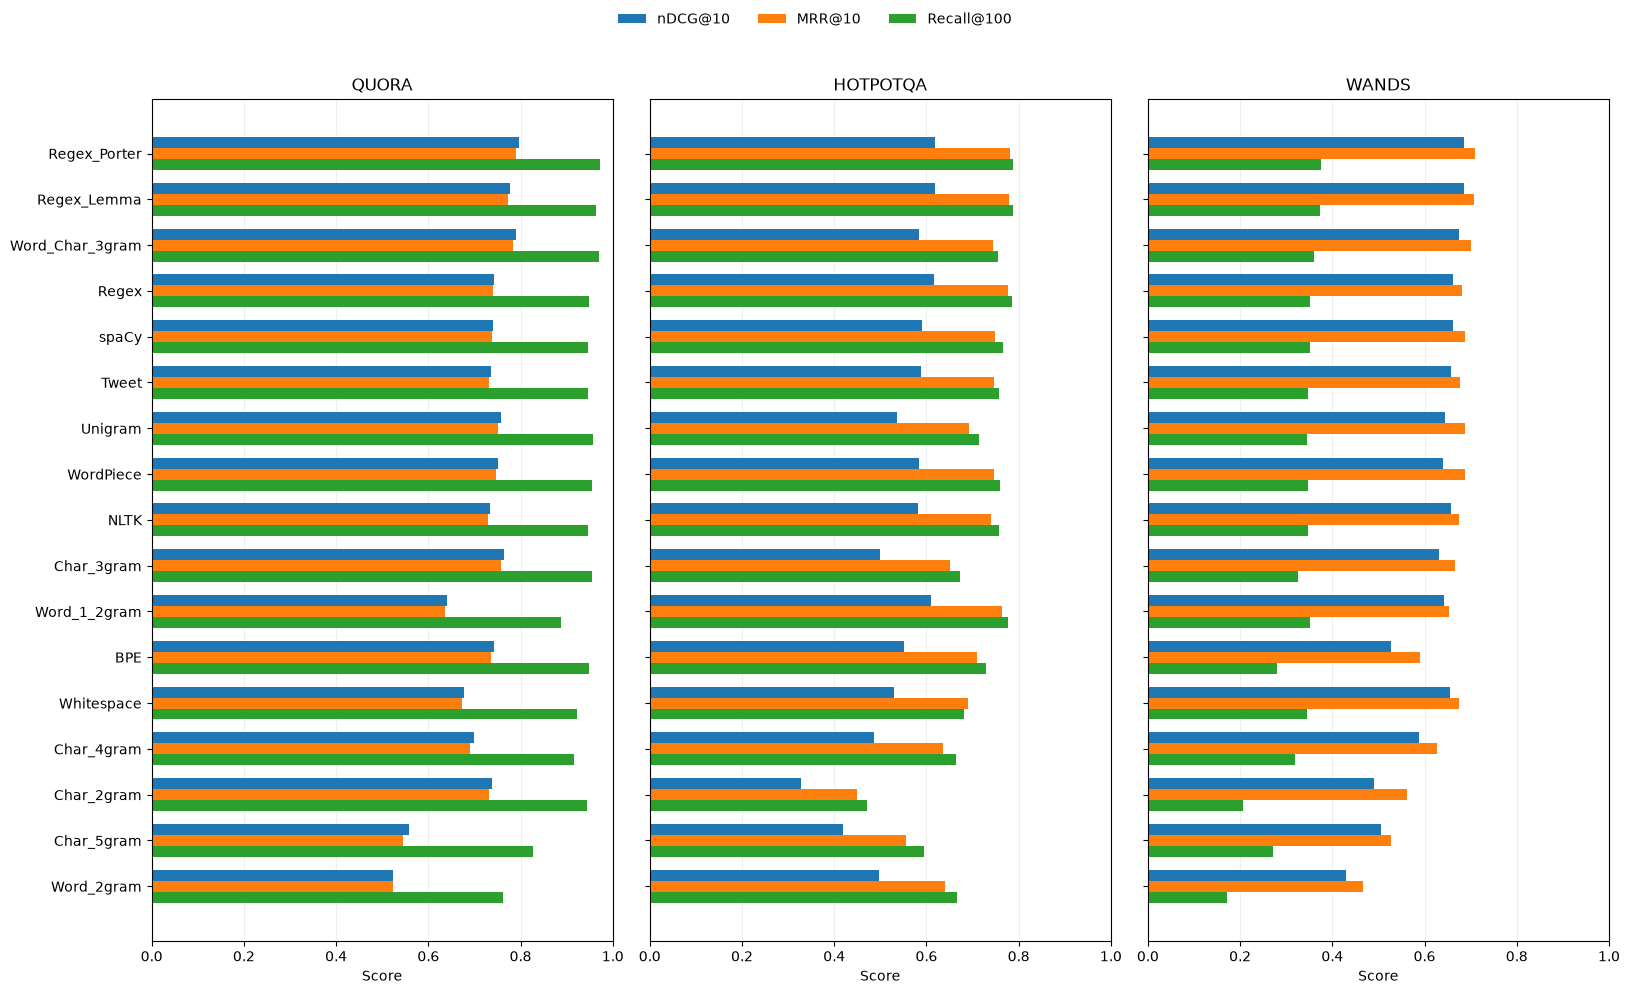

In [14]:
if all_dataset_results:
    summary_df = pd.concat(
        {dataset: df.set_index("Tokenizer")
         for dataset, df in all_dataset_results.items()},
        names=["Dataset"],
    )

    datasets_run = list(all_dataset_results)
    ndcg_pivot = summary_df["nDCG@10"].unstack("Dataset")[datasets_run]
    ndcg_pivot["AvgRank"] = ndcg_pivot.rank(ascending=False).mean(axis=1)
    ndcg_pivot["DatasetsEvaluated"] = ndcg_pivot[datasets_run].notna().sum(axis=1)
    ndcg_pivot = ndcg_pivot.sort_values("AvgRank")
    recall_pivot = summary_df["Recall@100"].unstack("Dataset")[datasets_run]

    if SHOW_FINAL_PLOT:
        names = ndcg_pivot.index.tolist()
        metrics = ["nDCG@10", "MRR@10", "Recall@100"]
        y = np.arange(len(names))
        height = 0.24
        fig, axes = plt.subplots(
            1, len(datasets_run), sharey=True, squeeze=False,
            figsize=(4.8 * len(datasets_run) + 2, max(4, 0.48 * len(names) + 1.8)),
        )
        for ax, dataset in zip(axes[0], datasets_run):
            data = all_dataset_results[dataset].set_index("Tokenizer").reindex(names)
            for i, metric in enumerate(metrics):
                ax.barh(y + (i - 1) * height, data[metric], height=height, label=metric)
            ax.set_title(dataset.upper())
            ax.set_xlim(0, 1.0)
            ax.set_xlabel("Score")
            ax.set_axisbelow(True)
            ax.grid(axis="x", alpha=0.2)
        axes[0, 0].set_yticks(y, names)
        axes[0, 0].invert_yaxis()
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=len(metrics), frameon=False)
        fig.tight_layout(rect=(0, 0, 1, 0.94))
        plt.show()

## Conclusions

**1. Punctuation is the cheapest win.** A one-line `\w+` regex beat whitespace by 6.7 points on Quora and 8.5 on HotpotQA in about the same time. On WANDS it was worth only 0.6, because there was little punctuation left to fix.

**2. Smarter word tokenizers did not help.** NLTK Treebank, NLTK Tweet and spaCy never beat the regex. They stayed within a point of it on Quora and WANDS and fell about 3 points behind on HotpotQA, while running 6 to 19 times slower. They keep `?` and `,` as tokens, which carry no signal for BM25.

**3. Normalization mattered most, but how much depends on the text.** Porter added 5.3 points over the regex on Quora, 2.4 on WANDS and 0.4 on HotpotQA. The lemmatizer was within 0.1 points of Porter on HotpotQA and WANDS in about a third of the time.

**4. Character n-grams work like a fuzzy stemmer.** Words + char 3-grams was second on Quora and third on WANDS, but on 5.2 million passages short character slices match too much and lose to the regex. 3-grams were the best length; 2-grams match almost anything and 5-grams are too long to bridge word forms.

**5. Pretrained subwords are not a free upgrade.** BERT, RoBERTa and T5 vocabularies helped slightly on Quora and lost on HotpotQA and WANDS. They were built for neural models, not for exact term matching. Vocabularies trained on each corpus (`SUBWORD_MODE = "train"`) were not tested here.

**6. Word bigrams hurt in the same index.** As rare terms they get a high IDF, so a single phrase match can outweigh several word matches, and they double document length. If phrases matter, a separate, lower-weighted field is the usual approach.

**Takeaway:** for BM25, how you normalize the text matters more than which tokenizer library you pick. Regex + Porter was best everywhere: +12.0 nDCG@10 over whitespace on Quora, +9.0 on HotpotQA and +2.9 on WANDS.

## Optional Export

Nothing is saved automatically. Call `export_results("some/folder")` to write the result tables, per-query scores, rankings and settings for every dataset you ran. Files with the same names in that folder are overwritten.

In [15]:
def export_results(output_dir):
    if not all_dataset_results:
        raise ValueError("Run at least one dataset before exporting results.")
    root = Path(output_dir)
    root.mkdir(parents=True, exist_ok=True)
    for dataset, results in all_dataset_results.items():
        artifacts = all_dataset_artifacts[dataset]
        results.to_csv(root / f"{dataset}_tokenizer_results.csv", index=False)
        artifacts["per_query"].to_csv(root / f"{dataset}_per_query_results.csv", index=False)
        artifacts["overlap"].to_csv(root / f"{dataset}_pairwise_overlap.csv", index=False)
        (root / f"{dataset}_config.json").write_text(
            json.dumps(artifacts["config"], indent=2), encoding="utf-8"
        )
        with (root / f"{dataset}_rankings.jsonl").open("w", encoding="utf-8") as f:
            for name, queries in artifacts["rankings"].items():
                for qid, doc_ids in queries.items():
                    f.write(json.dumps({"Tokenizer": name, "query_id": qid,
                                        "doc_ids": doc_ids}) + "\n")
        if artifacts["models"]:
            model_dir = root / "tokenizers" / dataset
            model_dir.mkdir(parents=True, exist_ok=True)
            for name, model in artifacts["models"].items():
                model.save(str(model_dir / f"{name}.json"))
    combined = pd.concat(
        {dataset: df.set_index("Tokenizer")
         for dataset, df in all_dataset_results.items()}, names=["Dataset"]
    )
    combined.reset_index().to_csv(root / "tokenization_summary.csv", index=False)


# Uncomment and provide your preferred directory only when ready to save:
# export_results("path/to/results")